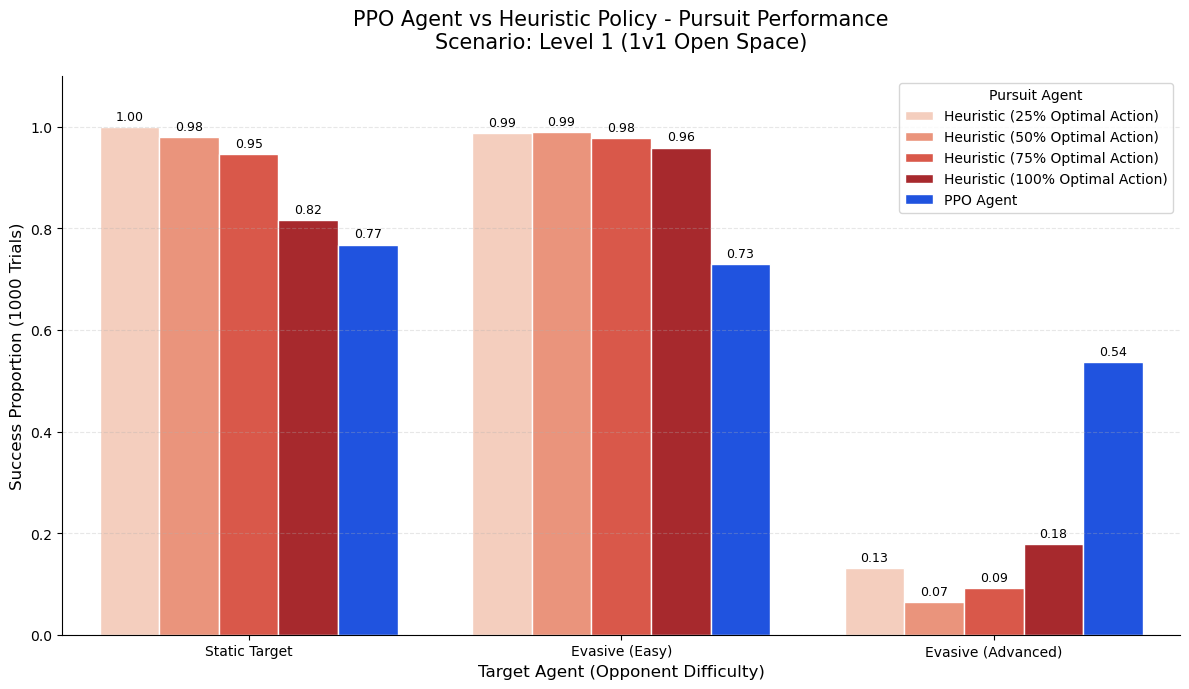

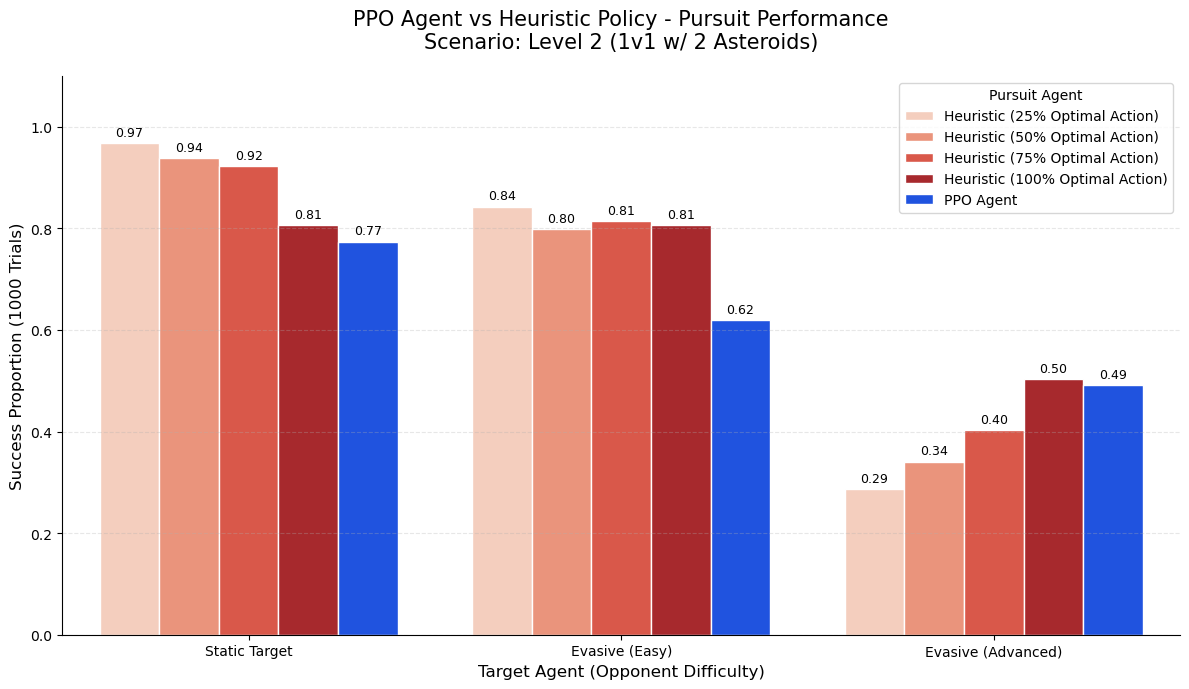

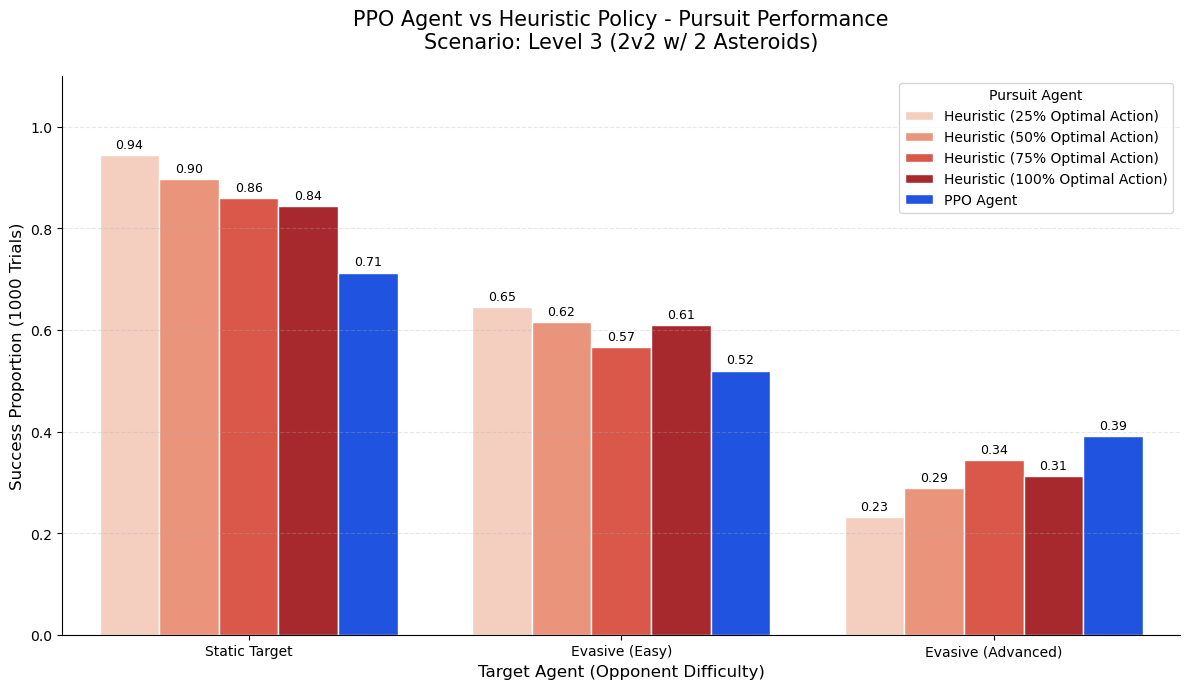

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("pursuit_evaluation_results.csv")

agent_mapping = {
    'heuristic_0.25': 'Heuristic (25% Optimal Action)',
    'heuristic_0.5': 'Heuristic (50% Optimal Action)',
    'heuristic_0.75': 'Heuristic (75% Optimal Action)',
    'heuristic_1.0': 'Heuristic (100% Optimal Action)',
    'dummy': 'Static Target',
    'evasion_heuristic_easy': 'Evasive (Easy)',
    'evasion_heuristic': 'Evasive (Advanced)',
    'ppo': 'PPO Agent'

}

df['Blue Agent'] = df['Blue Agent'].map(agent_mapping).fillna(df['Blue Agent'])
df['Red Agent'] = df['Red Agent'].map(agent_mapping).fillna(df['Red Agent'])

df['Blue Win Rate'] = df['Blue Wins'] / 1000.0

scenarios = df['Scenario'].unique()[:-1]

# 1. Define specific colors
# We use a gradient of Blues for heuristics and a distinct color (e.g., Orange or Purple) for PPO
heuristic_colors = sns.color_palette("Reds", 4)
ppo_color = "#0044FF" # A nice Red/Coral to make it pop
custom_palette = list(heuristic_colors) + [ppo_color]

# 2. Define explicit order for the X-axis
red_order = ['Static Target', 'Evasive (Easy)', 'Evasive (Advanced)']

for scenario in scenarios:
    df_scenario = df[df['Scenario'] == scenario].copy()
    
    # Ensure categorical order for the X-axis
    df_scenario['Red Agent'] = pd.Categorical(df_scenario['Red Agent'], categories=red_order, ordered=True)
    
    plt.figure(figsize=(12, 7))
    
    # 3. Create the plot with custom palette
    ax = sns.barplot(
        data=df_scenario, 
        x='Red Agent', 
        y='Blue Win Rate', 
        hue='Blue Agent',
        palette=custom_palette,
        edgecolor='white',
        linewidth=1
    )
    
    # 4. Add bar labels (Success Proportions)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)
    
    # Aesthetics
    plt.ylim(0, 1.1) # Extra room for labels
    plt.title(f'PPO Agent vs Heuristic Policy - Pursuit Performance\nScenario: {scenario}', fontsize=15, pad=20)
    plt.ylabel('Success Proportion (1000 Trials)', fontsize=12)
    plt.xlabel('Target Agent (Opponent Difficulty)', fontsize=12)
    
    # Clean up the legend
    plt.legend(title='Pursuit Agent', loc='upper right', frameon=True)
    
    sns.despine() # Removes top and right borders for a cleaner look
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    
    plt.show()

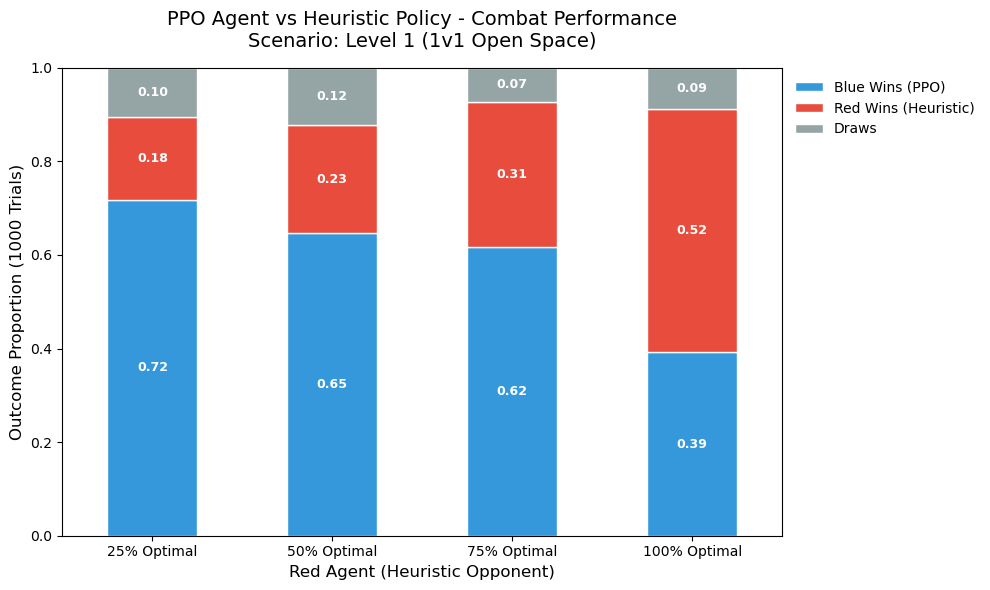

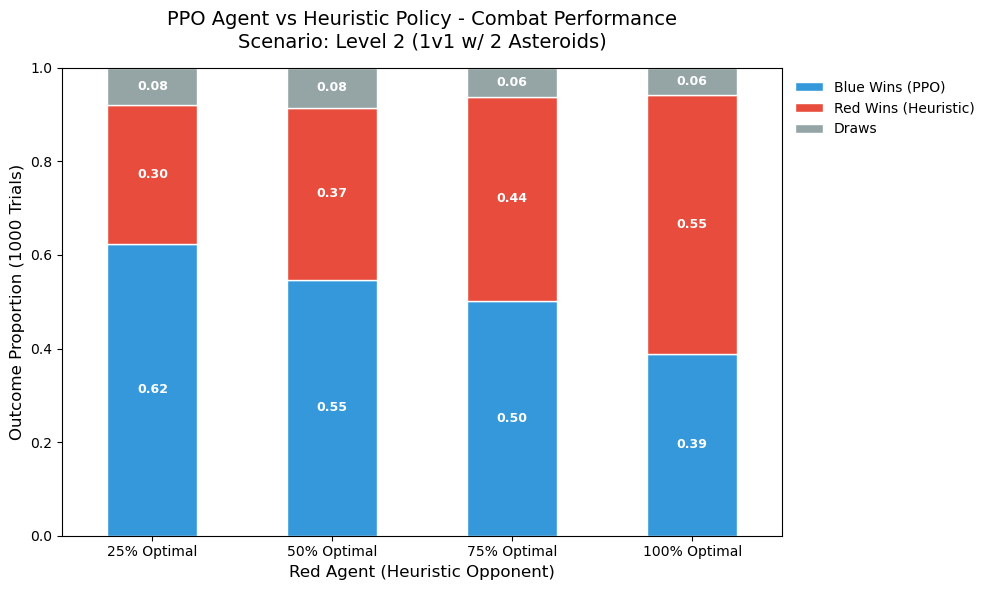

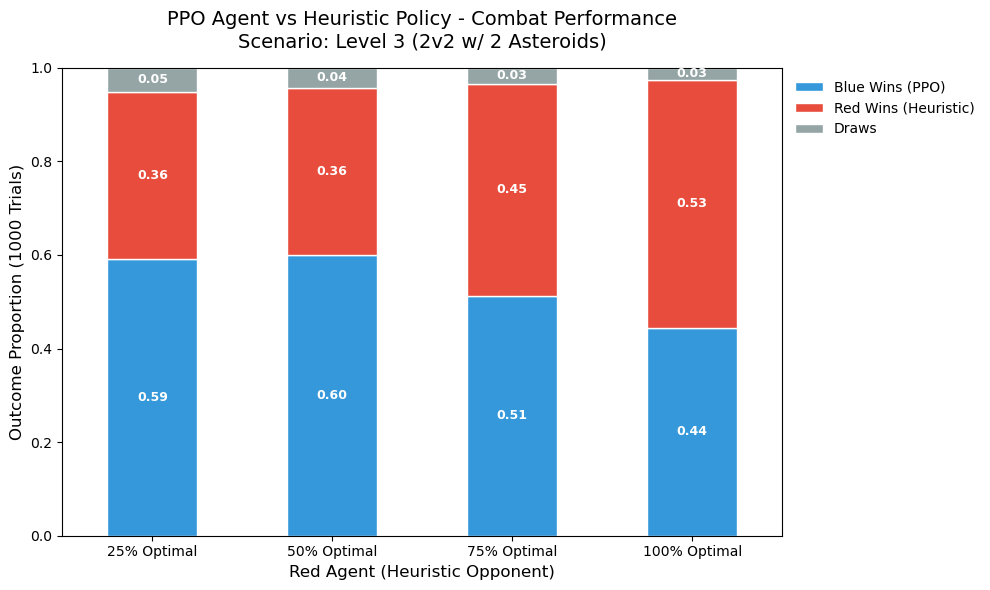

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("combat_evaluation_results.csv")

agent_mapping = {
    'heuristic_0.25': '25% Optimal',
    'heuristic_0.5': '50% Optimal',
    'heuristic_0.75': '75% Optimal',
    'heuristic_1.0': '100% Optimal',
    'dummy': 'Static Target',
    'evasion_heuristic_easy': 'Evasive (Easy)',
    'evasion_heuristic': 'Evasive (Advanced)',
    'ppo': 'PPO Agent'

}

# 1. Apply mapping (using your existing agent_mapping)
df['Blue Agent'] = df['Blue Agent'].map(agent_mapping).fillna(df['Blue Agent'])
df['Red Agent'] = df['Red Agent'].map(agent_mapping).fillna(df['Red Agent'])

# 2. Calculate proportions
# We sum all result columns to get the total games per row (usually 1000)
total_games = df[['Blue Wins', 'Red Wins', 'Draws (Time)', 'Draws (Mutual)']].sum(axis=1)

df['Blue Win Prop'] = df['Blue Wins'] / total_games
df['Red Win Prop'] = df['Red Wins'] / total_games
df['Draw Prop'] = (df['Draws (Time)'] + df['Draws (Mutual)']) / total_games

# 3. Define the order of Red Agents for the X-axis
red_order = [
    '25% Optimal', 
    '50% Optimal', 
    '75% Optimal', 
    '100% Optimal'
]

scenarios = df['Scenario'].unique()[:-1]

for scenario in scenarios:
    # Filter for scenario and ensure only PPO is the Blue Agent
    df_scenario = df[(df['Scenario'] == scenario) & (df['Blue Agent'] == 'PPO Agent')].copy()
    
    # Set the index to Red Agent and sort by our difficulty order
    df_scenario['Red Agent'] = pd.Categorical(df_scenario['Red Agent'], categories=red_order, ordered=True)
    df_scenario = df_scenario.sort_values('Red Agent')
    
    # Prepare data for stacking: X-axis is Red Agent, Y is the three outcome proportions
    plot_data = df_scenario.set_index('Red Agent')[['Blue Win Prop', 'Red Win Prop', 'Draw Prop']]
    
    # 4. Create the Stacked Bar Chart
    # Colors: Blue for wins, Red for losses, Grey for draws
    ax = plot_data.plot(
        kind='bar', 
        stacked=True, 
        figsize=(10, 6),
        color=['#3498db', '#e74c3c', '#95a5a6'], 
        edgecolor='white'
    )
    
    # Aesthetics
    plt.title(f'PPO Agent vs Heuristic Policy - Combat Performance\nScenario: {scenario}', fontsize=14, pad=15)
    plt.ylabel('Outcome Proportion (1000 Trials)', fontsize=12)
    plt.xlabel('Red Agent (Heuristic Opponent)', fontsize=12)
    plt.xticks(rotation=0) # Keeps agent names horizontal
    plt.ylim(0, 1)
    
    # Legend labels
    plt.legend(['Blue Wins (PPO)', 'Red Wins (Heuristic)', 'Draws'], 
               bbox_to_anchor=(1.0, 1.0), loc='upper left', frameon=False)

    # 5. Add percentage labels inside the bars
    for n, x in enumerate([*ax.containers]):
        # Only show labels if the segment is large enough to read (> 5%)
        ax.bar_label(x, fmt='%.2f', label_type='center', color='white', weight='bold', fontsize=9)

    plt.tight_layout()
    plt.show()

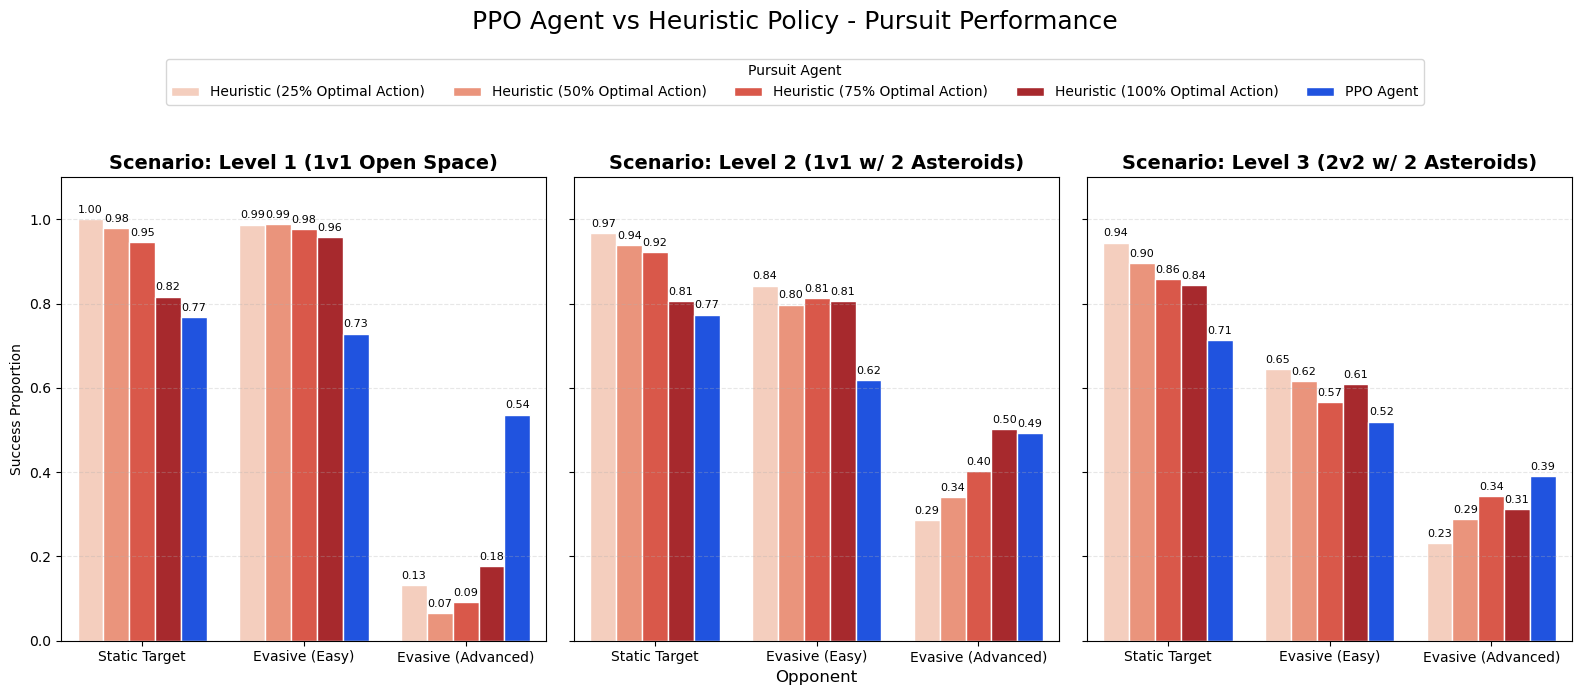

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and process Pursuit data
df_p = pd.read_csv("pursuit_evaluation_results.csv")

agent_mapping_p = {
    'heuristic_0.25': 'Heuristic (25% Optimal Action)',
    'heuristic_0.5': 'Heuristic (50% Optimal Action)',
    'heuristic_0.75': 'Heuristic (75% Optimal Action)',
    'heuristic_1.0': 'Heuristic (100% Optimal Action)',
    'dummy': 'Static Target',
    'evasion_heuristic_easy': 'Evasive (Easy)',
    'evasion_heuristic': 'Evasive (Advanced)',
    'ppo': 'PPO Agent',
    'Red Agent': "Opponent"
}

df_p['Blue Agent'] = df_p['Blue Agent'].map(agent_mapping_p).fillna(df_p['Blue Agent'])
df_p['Red Agent'] = df_p['Red Agent'].map(agent_mapping_p).fillna(df_p['Red Agent'])
df_p['Blue Win Rate'] = df_p['Blue Wins'] / 1000.0

# Setup 1x3 Grid
scenarios_p = df_p['Scenario'].unique()[:-1]
red_order_p = ['Static Target', 'Evasive (Easy)', 'Evasive (Advanced)']
heuristic_colors = sns.color_palette("Reds", 4)
ppo_color = "#0044FF" 
custom_palette = list(heuristic_colors) + [ppo_color]

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

for i, scenario in enumerate(scenarios_p):
    ax = axes[i]
    df_scenario = df_p[df_p['Scenario'] == scenario].copy()
    df_scenario['Red Agent'] = pd.Categorical(df_scenario['Red Agent'], categories=red_order_p, ordered=True)
    
    sns.barplot(
        data=df_scenario, 
        x='Red Agent', 
        y='Blue Win Rate', 
        hue='Blue Agent',
        palette=custom_palette,
        edgecolor='white',
        ax=ax
    )

    #ax.set_xlabel('Opponent', fontsize=12) 
    ax.set_xlabel('Opponent' if i == 1 else '', fontsize=12)
    
    ax.set_title(f'Scenario: {scenario}', fontsize=14, fontweight='bold')
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('Success Proportion' if i == 0 else "")
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    ax.get_legend().remove()
    
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=3, fontsize=8)

# Shared Legend at top
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Pursuit Agent', loc='upper center', 
           bbox_to_anchor=(0.5, 1.08), ncol=5, frameon=True)

plt.suptitle('PPO Agent vs Heuristic Policy - Pursuit Performance', fontsize=18, y=1.15)
plt.tight_layout()
plt.show()

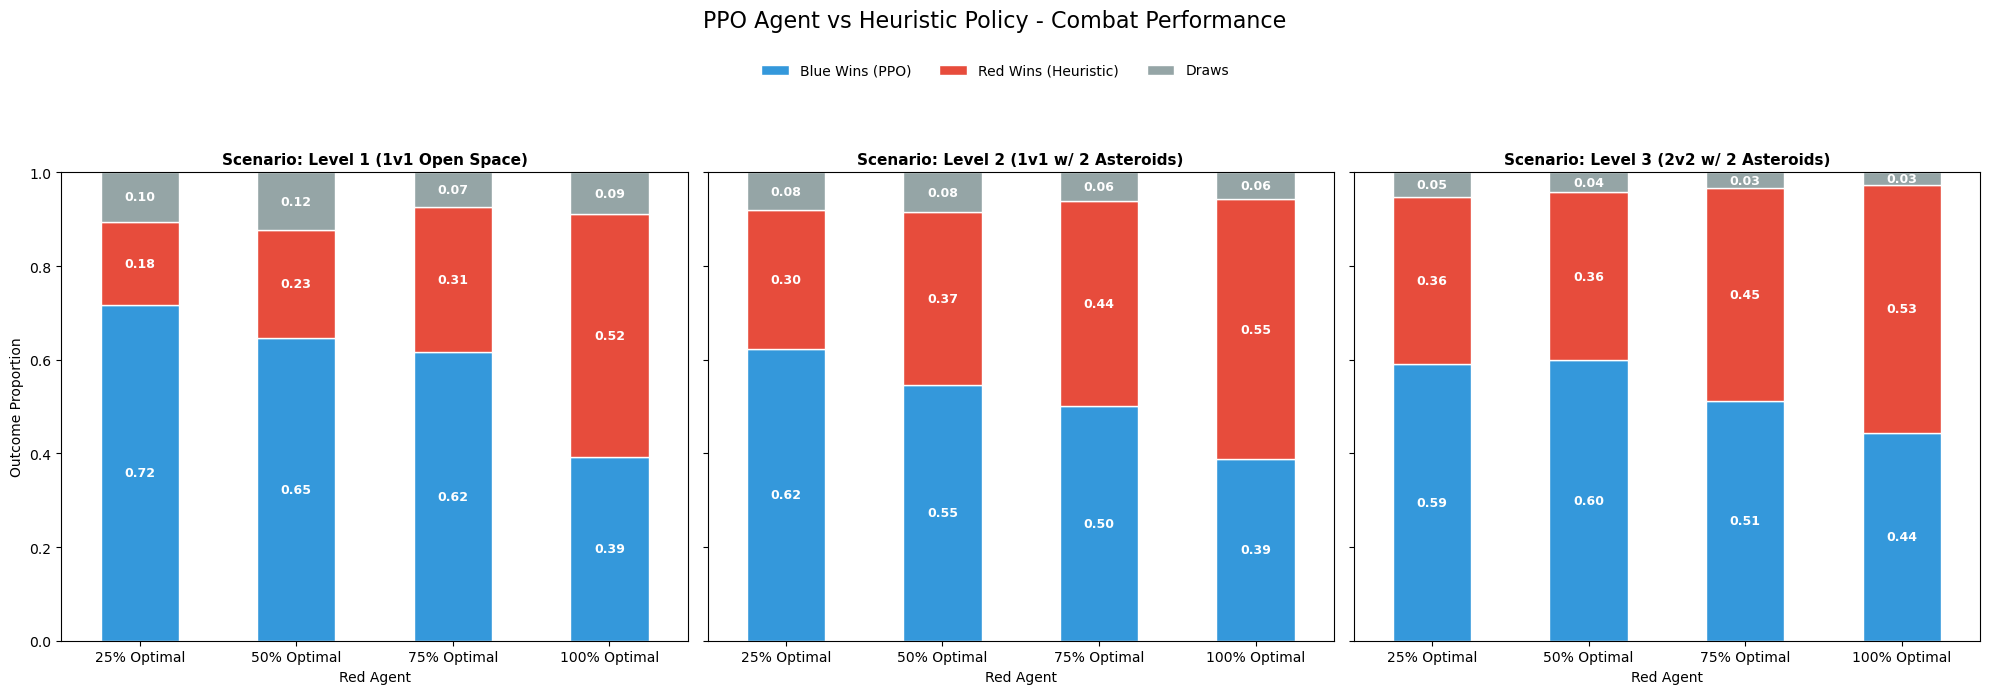

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Load and process Combat data
df_c = pd.read_csv("combat_evaluation_results.csv")

agent_mapping_c = {
    'heuristic_0.25': '25% Optimal',
    'heuristic_0.5': '50% Optimal',
    'heuristic_0.75': '75% Optimal',
    'heuristic_1.0': '100% Optimal',
    'ppo': 'PPO Agent'
}

df_c['Blue Agent'] = df_c['Blue Agent'].map(agent_mapping_c).fillna(df_c['Blue Agent'])
df_c['Red Agent'] = df_c['Red Agent'].map(agent_mapping_c).fillna(df_c['Red Agent'])

# Calculate proportions
total_games = df_c[['Blue Wins', 'Red Wins', 'Draws (Time)', 'Draws (Mutual)']].sum(axis=1)
df_c['Blue Win Prop'] = df_c['Blue Wins'] / total_games
df_c['Red Win Prop'] = df_c['Red Wins'] / total_games
df_c['Draw Prop'] = (df_c['Draws (Time)'] + df_c['Draws (Mutual)']) / total_games

scenarios_c = df_c['Scenario'].unique()[:-1]
red_order_c = ['25% Optimal', '50% Optimal', '75% Optimal', '100% Optimal']

# Setup 1x3 Grid
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

for i, scenario in enumerate(scenarios_c):
    ax = axes[i]
    df_scenario = df_c[(df_c['Scenario'] == scenario) & (df_c['Blue Agent'] == 'PPO Agent')].copy()
    df_scenario['Red Agent'] = pd.Categorical(df_scenario['Red Agent'], categories=red_order_c, ordered=True)
    df_scenario = df_scenario.sort_values('Red Agent')
    
    plot_data = df_scenario.set_index('Red Agent')[['Blue Win Prop', 'Red Win Prop', 'Draw Prop']]
    
    plot_data.plot(
        kind='bar', 
        stacked=True, 
        ax=ax,
        color=['#3498db', '#e74c3c', '#95a5a6'], 
        edgecolor='white',
        legend=False
    )
    
    ax.set_title(f'Scenario: {scenario}', fontsize=11, fontweight='bold')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_ylabel('Outcome Proportion' if i == 0 else "")
    ax.set_ylim(0, 1)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', label_type='center', color='white', weight='bold', fontsize=9)

# Shared Legend at top
fig.legend(['Blue Wins (PPO)', 'Red Wins (Heuristic)', 'Draws'], 
           loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=False)

plt.suptitle('PPO Agent vs Heuristic Policy - Combat Performance', fontsize=16, y=1.15)
plt.tight_layout()
plt.show()

C:\Users\skyec\AppData\Local\Temp\ipykernel_27172\228051383.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


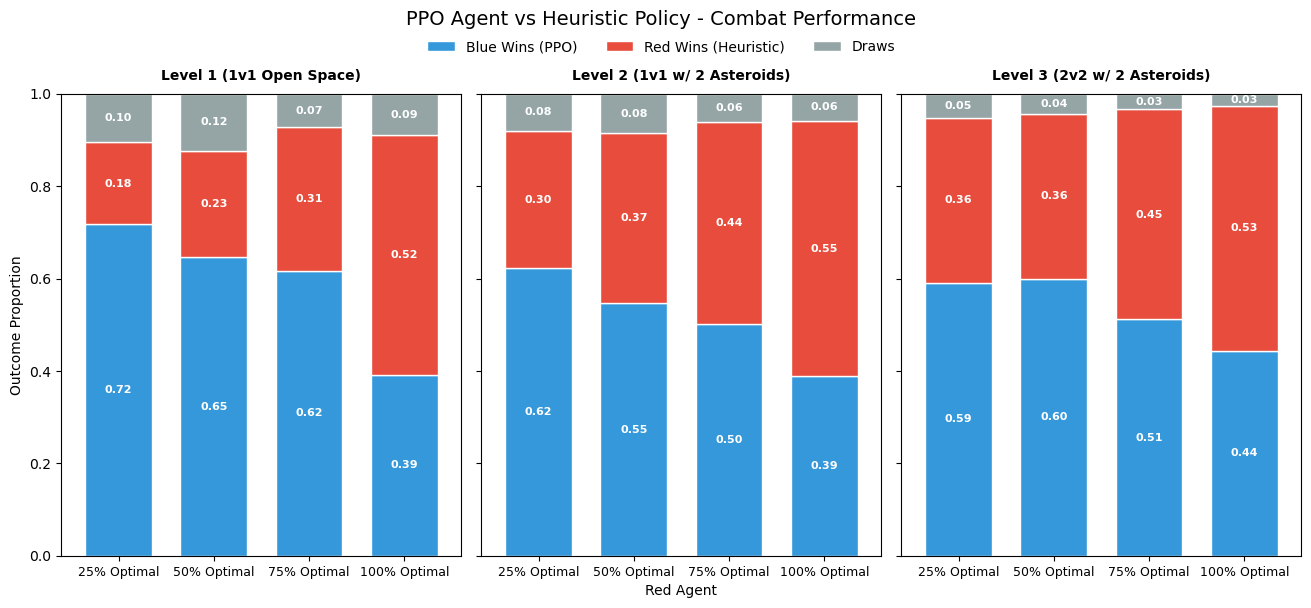

In [22]:
# Combat Evaluation - Tightened 1 Row x 3 Columns
# Reduced figsize width from 20/22 to 16
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True, 
                         gridspec_kw={'wspace': 0.05}) # wspace=0.05 removes gaps between subplots

for i, scenario in enumerate(scenarios_c):
    ax = axes[i]
    df_scenario = df_c[(df_c['Scenario'] == scenario) & (df_c['Blue Agent'] == 'PPO Agent')].copy()
    df_scenario['Red Agent'] = pd.Categorical(df_scenario['Red Agent'], categories=red_order_c, ordered=True)
    df_scenario = df_scenario.sort_values('Red Agent')
    
    plot_data = df_scenario.set_index('Red Agent')[['Blue Win Prop', 'Red Win Prop', 'Draw Prop']]
    
    # width=0.8 makes the bars wider relative to their slot
    plot_data.plot(
        kind='bar', 
        stacked=True, 
        ax=ax,
        color=['#3498db', '#e74c3c', '#95a5a6'], 
        edgecolor='white',
        width=0.7, 
        legend=False
    )
    
    # Title inside the axis or very close to it
    ax.set_title(scenario, fontsize=10, fontweight='bold', pad=10)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=9)
    ax.set_xlabel('Red Agent' if i == 1 else "") # Only label the middle X-axis
    ax.set_ylabel('Outcome Proportion' if i == 0 else "")
    ax.set_ylim(0, 1)

    # Percentage labels
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', label_type='center', color='white', weight='bold', fontsize=8)

# Shared Legend - Adjusted bbox to be closer to the plots
fig.legend(['Blue Wins (PPO)', 'Red Wins (Heuristic)', 'Draws'], 
           loc='upper center', bbox_to_anchor=(0.5, .99), ncol=3, frameon=False, fontsize=10)

# Suptitle - Lowered 'y' to sit tighter to the legend
plt.suptitle('PPO Agent vs Heuristic Policy - Combat Performance', fontsize=14, y=1.02)

# Use rect to ensure the suptitle/legend don't overlap but keep the layout compact
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()